# Side-by-side team comparison: Khoi, Nguyen, and Alka

**Khoi:** newest literal-profile SmallResNet/MNIST run, **96.5%**.  
**Nguyen:** updated SmallResNet/CIFAR run, **43.2%**, as exported in Alka's latest combined CSV.  
**Alka:** GaussianNB/CIFAR run, **20.6%**, from that same published CSV.

All use 9,000 training examples, 1,000 validation examples, batch size 32, and one pass. This is a descriptive comparison, **not a controlled three-way model ranking**: MNIST differs from CIFAR in images and true class count, and GaussianNB differs from the neural pipelines in representation and preprocessing.

This notebook reads archived evidence without training, downloads or official test evaluation. Missing metrics are explicitly unavailable. Khoi's model was independently re-evaluated locally; Nguyen/Alka records were read and checked for consistency, not rerun.

In [1]:
from pathlib import Path
import hashlib
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "configs/mnist_nguyen_literal.yaml").exists())
SRC = ROOT / "results/team_comparison_sources"
RUN = ROOT / "results/mnist_nguyen_literal_seed42"
OUT = ROOT / "results/team_comparison"
OUT.mkdir(exist_ok=True)
provenance = json.loads((SRC / "provenance.json").read_text())
raw = (SRC / "alka_nguyen_results.csv").read_bytes()
assert hashlib.sha1(f"blob {len(raw)}\0".encode() + raw).hexdigest() == provenance["alka_combined_csv_git_blob"]
team = pd.read_csv(SRC / "alka_nguyen_results.csv")
khoi = pd.read_csv(RUN / "results.csv")
nguyen = team[team.run_id == provenance["nguyen_combined_csv_alias"]].sort_values("examples_processed")
alka = team[team.run_id == "gaussiannb_seed42"].sort_values("examples_processed")
meta = json.loads((RUN / "run.json").read_text())
audit = json.loads((RUN / "audit/audit.json").read_text())
cfg = meta["config"]
ng_cfg = json.loads((SRC / "nguyen_notebook_config.json").read_text())
frames = {"Khoi: MNIST / SmallResNet": khoi,
          "Nguyen: CIFAR / SmallResNet": nguyen,
          "Alka: CIFAR / GaussianNB": alka}
expected = [0,1024,2016,3008,4000,5024,6016,7008,8000,9000]
for name, frame in frames.items():
    assert len(frame) and frame.run_id.nunique() == 1
    assert set(frame.eval_split) == {"validation"}
    assert frame.examples_processed.is_monotonic_increasing
    assert not frame.examples_processed.duplicated().any()
    assert frame.accuracy.between(0,1).all()
    assert frame.iloc[-1].examples_processed == 9000 and frame.iloc[-1].updates == 282
    assert set(frame.batch_size) == {32}
    assert set(frame.model_seed) == set(frame.stream_seed) == {42}
assert khoi.examples_processed.tolist() == nguyen.examples_processed.tolist() == expected
assert alka.examples_processed.tolist() == expected[1:]
assert set(nguyen.learning_rate) == {0.0005}
assert nguyen.iloc[-1].accuracy == .432 and alka.iloc[-1].accuracy == .206
assert cfg["learning_rate"] == ng_cfg["lr"] == .0005
assert cfg["weight_decay"] == ng_cfg["weight_decay"] == .0005
assert cfg["pct_start"] == ng_cfg["pct_start"] == .15
assert cfg["dropout"] == ng_cfg["dropout"] == .2
for metric, value in audit["metrics"].items():
    assert abs(value - float(khoi.iloc[-1][metric])) < 1e-12
assert audit["correct"] == 965 and audit["validation_examples"] == 1000
assert audit["training_class_counts"] == [900]*10
assert audit["validation_class_counts"] == [100]*10
assert audit["train_validation_overlap"] == 0 and audit["num_outputs"] == 100
print("Source CSV fingerprint, run identities, checkpoint counts and MNIST checkpoint audit verified.")
print("Nguyen original run:", provenance["nguyen_original_run_id"])
print("Combined CSV alias:", provenance["nguyen_combined_csv_alias"])
print("Source branch pinned at:", provenance["alka_branch_commit"])

Source CSV fingerprint, run identities, checkpoint counts and MNIST checkpoint audit verified.
Nguyen original run: online_c20_m42_s42_20261028-173041
Combined CSV alias: resnet_nguyen_seed42
Source branch pinned at: 10c9ef76da8df1de3ab97410df20c0c2f40b8258


## Settings side by side

**Why per-class counts differ:** MNIST has ten real digit classes; CIFAR has twenty selected object classes. Both keep a balanced 90%/10% split and the same 9,000/1,000 totals. MNIST therefore has 900/100 per digit; CIFAR has 450/50 per class. Using 450/50 for MNIST would reduce its totals to 4,500/500. A 100-output head does not create 100 real training classes.

Nguyen's settings are linked to his published notebook and Alka's handoff record. Alka's representation/timing are documented in her published code/report. Shared CIFAR source order is reported by Alka, but was not independently reverified here because the original saved split artifact is absent.

In [2]:
settings = pd.DataFrame({
 "Setting": ["Dataset / real labels", "Model", "Original image", "Model input", "Output head",
    "Train / validation", "Per-class train / validation", "Training rule", "Batch / updates / final batch",
    "Model / split / stream seeds", "Optimizer / update", "Max learning rate / schedule",
    "Weight decay", "Dropout", "Train preprocessing", "Model normalization", "Validation preprocessing",
    "Validation batch / workers", "Device", "Checkpoint comparison"],
 "Khoi — newest MNIST": ["MNIST / digits 0–9 (10 classes)", "Three-stage SmallResNet", "1×28×28 grayscale",
    "3×32×32: resized, grayscale copied to RGB", "100; unmasked predictions",
    "9,000 / 1,000; audit verified", "900 / 100 × 10 classes", "One pass; no replay", "32 / 282 / 8",
    "42 / 42 / 42", "AdamW", "0.0005 / OneCycleLR; pct_start 0.15", "0.0005", "0.2",
    "[0,1]; crop 32, reflect pad 4; horizontal flip 0.5", "CIFAR mean/std, once inside model",
    "Resize+RGB adaptation, then scaling only", "256 / 2", "CPU; CUDA unavailable",
    "0 then same complete-batch counts through 9,000"],
 "Nguyen — CIFAR SmallResNet": ["CIFAR-100 / labels 0–19 (20 classes)", "Three-stage SmallResNet", "3×32×32 RGB",
    "3×32×32 native RGB", "100; unmasked predictions", "9,000 / 1,000; team record",
    "450 / 50 × 20 classes", "One pass; no replay", "32 / 282 / 8", "42 / 42 / 42", "AdamW",
    "0.0005 / OneCycleLR; pct_start 0.15", "0.0005", "0.2",
    "[0,1]; crop 32, reflect pad 4; horizontal flip 0.5", "CIFAR mean/std, once inside model",
    "Scaling only; no random augmentation", "256 / 2", "Tesla T4 CUDA (team report)",
    "0 then same complete-batch counts through 9,000"],
 "Alka — CIFAR GaussianNB": ["CIFAR-100 / labels 0–19 (20 classes)", "Gaussian Naive Bayes", "3×32×32 RGB",
    "Flattened 3,072 scaled pixel features", "20 modeled classes", "9,000 / 1,000; team record",
    "450 / 50 × 20 classes (reported shared split)", "One pass; no replay", "32 / 282 / 8", "42 / shared split / 42",
    "partial_fit on one persistent GaussianNB", "Not applicable", "Not applicable", "Not applicable",
    "[0,1], flatten; no crop or flip", "None", "[0,1], flatten; no random augmentation",
    "32 / not recorded in exported run metadata", "CPU (team report)",
    "Same nonzero counts; no pretraining prediction available"],
}).set_index("Setting")
with pd.option_context("display.max_colwidth", 110): display(settings)
settings.to_csv(OUT / "settings.csv")

,Khoi — newest MNIST,Nguyen — CIFAR SmallResNet,Alka — CIFAR GaussianNB
Setting,,,
Dataset / real labels,MNIST / digits 0–9 (10 classes),CIFAR-100 / labels 0–19 (20 classes),CIFAR-100 / labels 0–19 (20 classes)
Model,Three-stage SmallResNet,Three-stage SmallResNet,Gaussian Naive Bayes
Original image,1×28×28 grayscale,3×32×32 RGB,3×32×32 RGB
Model input,"3×32×32: resized, grayscale copied to RGB",3×32×32 native RGB,"Flattened 3,072 scaled pixel features"
Output head,100; unmasked predictions,100; unmasked predictions,20 modeled classes
Train / validation,"9,000 / 1,000; audit verified","9,000 / 1,000; team record","9,000 / 1,000; team record"
Per-class train / validation,900 / 100 × 10 classes,450 / 50 × 20 classes,450 / 50 × 20 classes (reported shared split)
Training rule,One pass; no replay,One pass; no replay,One pass; no replay
Batch / updates / final batch,32 / 282 / 8,32 / 282 / 8,32 / 282 / 8


## Final validation results and reported timing

Missing precision/recall/F1 values cannot be reconstructed from accuracy alone. The CIFAR exports do not contain those metrics. We do not invent them.

Timing scopes differ: Khoi measures forward/backward/optimizer computation on CPU, excluding loading/evaluation; Alka measures CPU `partial_fit` only. Nguyen's notebook reports elapsed training time excluding validation but including other loop/loading overhead, on a Tesla T4. The values below are source-reported durations, **not an end-to-end speed ranking**. No speedup ratio is computed.

In [3]:
columns = list(frames)
kf, nf, af = [frames[key].iloc[-1] for key in columns]
results = pd.DataFrame({
 "Metric": ["Final validation accuracy", "Macro precision", "Macro recall", "Macro F1",
            "Correct / validation count", "Training examples / updates", "Reported training/update seconds",
            "Timed run wall seconds", "Evidence"],
 columns[0]: [f"{100*kf.accuracy:.2f}%", f"{100*kf.precision:.2f}%", f"{100*kf.recall:.2f}%", f"{kf.f1:.4f}",
    "965 / 1,000", "9,000 / 282", f"{meta['training_seconds']:.3f}", f"{meta['total_wall_seconds']:.3f}",
    "Local saved-checkpoint re-evaluation; all metrics reproduced"],
 columns[1]: [f"{100*nf.accuracy:.2f}%", "Unavailable", "Unavailable", "Unavailable",
    "432 / 1,000 implied by reported accuracy/count", "9,000 / 282", f"{nf.training_seconds:.3f}", "Unavailable",
    "Alka's combined CSV + handoff mapping to Nguyen's updated run"],
 columns[2]: [f"{100*af.accuracy:.2f}%", "Unavailable", "Unavailable", "Unavailable",
    "206 / 1,000 implied by reported accuracy/count", "9,000 / 282", f"{af.training_seconds:.3f}", "Unavailable",
    "Published GaussianNB export and experiment summary"],
}).set_index("Metric")
with pd.option_context("display.max_colwidth", 110): display(results)
results.to_csv(OUT / "final_results.csv")

,Khoi: MNIST / SmallResNet,Nguyen: CIFAR / SmallResNet,Alka: CIFAR / GaussianNB
Metric,,,
Final validation accuracy,96.50%,43.20%,20.60%
Macro precision,96.53%,Unavailable,Unavailable
Macro recall,96.50%,Unavailable,Unavailable
Macro F1,0.9650,Unavailable,Unavailable
Correct / validation count,"965 / 1,000","432 / 1,000 implied by reported accuracy/count","206 / 1,000 implied by reported accuracy/count"
Training examples / updates,"9,000 / 282","9,000 / 282","9,000 / 282"
Reported training/update seconds,157.632,4.651,0.788
Timed run wall seconds,365.371,Unavailable,Unavailable
Evidence,Local saved-checkpoint re-evaluation; all metrics reproduced,Alka's combined CSV + handoff mapping to Nguyen's updated run,Published GaussianNB export and experiment summary


## Learning curves: same axes, separate experiments

All panels use 0–100% and 0–9,000 training images. GaussianNB starts at its first evaluation after 1,024 examples, because the unfitted classifier cannot predict. No zero-example accuracy is fabricated.

Matching counts does not equate task difficulty. MNIST and CIFAR are different validation populations, and the neural/non-neural models use different representations.

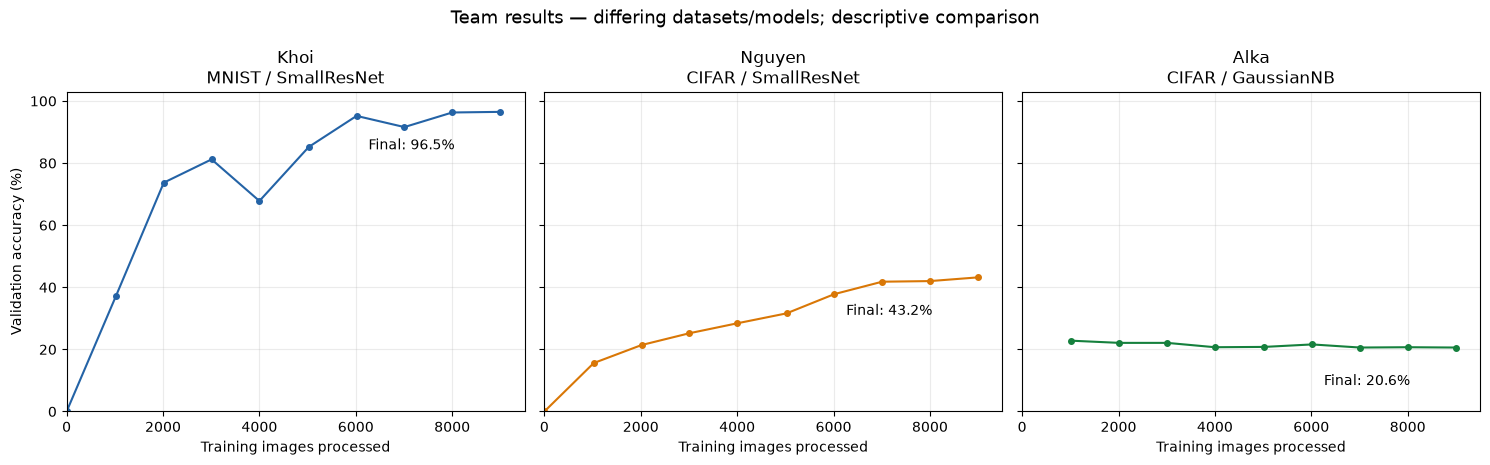

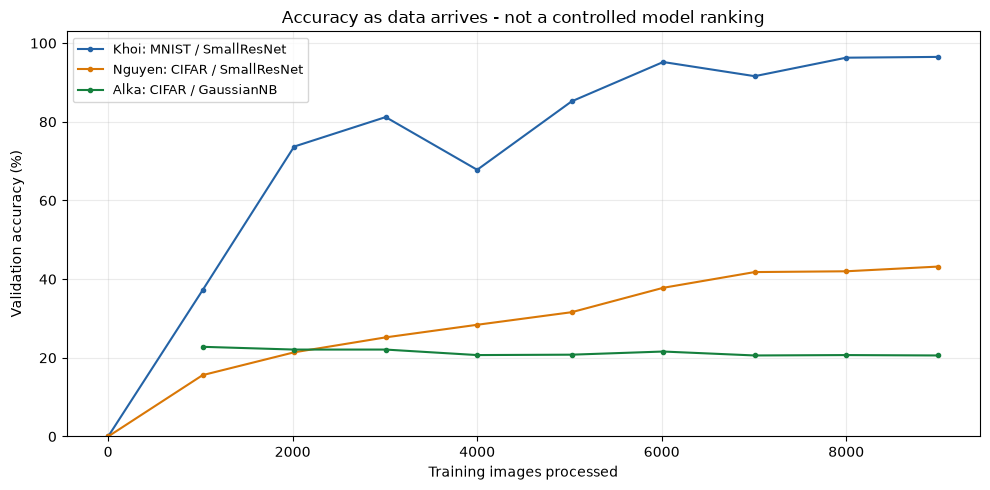

In [4]:
colors=["#2463A6","#D97706","#15803D"]
fig, axes=plt.subplots(1,3,figsize=(15,4.7),sharex=True,sharey=True)
for ax,(name,frame),color in zip(axes,frames.items(),colors):
    ax.plot(frame.examples_processed,100*frame.accuracy,marker="o",ms=4,color=color)
    last=frame.iloc[-1]
    ax.annotate(f"Final: {100*last.accuracy:.1f}%",(last.examples_processed,100*last.accuracy),
                xytext=(-95,-27),textcoords="offset points",fontsize=10)
    ax.set(title=name.replace(": ","\n"),xlabel="Training images processed",xlim=(0,9500),ylim=(0,103))
    ax.grid(alpha=.25)
axes[0].set_ylabel("Validation accuracy (%)")
fig.suptitle("Team results — differing datasets/models; descriptive comparison",fontsize=13)
fig.tight_layout()
fig.savefig(OUT / "side_by_side_learning_curves.png",dpi=160,bbox_inches="tight")
plt.show()

fig,ax=plt.subplots(figsize=(10,5))
for (name,frame),color in zip(frames.items(),colors):
    ax.plot(frame.examples_processed,100*frame.accuracy,marker=".",label=name,color=color)
ax.set(xlabel="Training images processed",ylabel="Validation accuracy (%)",ylim=(0,103),
       title="Accuracy as data arrives - not a controlled model ranking")
ax.grid(alpha=.25);ax.legend(fontsize=9);fig.tight_layout()
fig.savefig(OUT / "combined_learning_curves.png",dpi=160,bbox_inches="tight")
plt.show()

## Interpretation and critical discussion

1. **Khoi, 96.5%:** the literal CIFAR-style SmallResNet protocol learns MNIST effectively in one pass. The checkpoint audit reproduced 965 correct predictions from 1,000 validation images, with zero split overlap. This supports the implementation and dataset-adaptation contribution; it is not official-test accuracy or proof of continual-learning robustness under distribution shifts.
2. **Nguyen, 43.2%:** accuracy rises over the published CIFAR stream, from 15.6% at 1,024 examples to 43.2% at 9,000. CIFAR contains more varied objects/backgrounds and twenty selected labels, versus ten MNIST digits. The higher MNIST score is not evidence that Khoi's method is intrinsically better.
3. **Alka, 20.6%:** GaussianNB begins at 22.8% after 1,024 examples and stays around 20–23%. The independent-feature assumption may limit flattened-image learning, but this one run does not establish the cause. It offers a lightweight incremental baseline.
4. **Matched versus different:** the two neural runs align optimizer, head/input format, normalization, augmentation family, counts and checkpoint schedule. Native MNIST still requires resizing/channel replication; the tasks, true class counts, split memberships and hardware differ. CIFAR statistics and horizontal flips are intentional literal-profile choices, not necessarily suitable MNIST preprocessing.
5. **CIFAR stream evidence:** Alka reports exact shared order with Nguyen. The archived handoff says this review has not independently reproduced that check, and the original split artifact is still needed. Do not convert a reported check into an independently verified claim.
6. **Limits:** one run/seed each, different metric availability and timing scopes, and no independently reloaded CIFAR checkpoints here. Nguyen's notebook also has a train-mode dummy shape forward that can update BatchNorm; Khoi's implementation does not reproduce that behavior. Avoid causal or hardware-speed claims.

### Next useful experiment

Retain these as baseline records. Obtain original CIFAR run metadata/split/checkpoints, export precision/recall/F1 for both CIFAR models, and verify the shared CIFAR source membership/order. Repeated seeds would strengthen estimates. Testing Khoi's original Adam configuration on CIFAR is a **separate future experiment**; these plots do not claim it has been run.

## Provenance and reproduction

The newer **43.2% / LR 0.0005** record is now available through Alka's updated combined CSV. It is a different run from the older **39.5% / LR 0.002** CSV on main. The older record is excluded from these charts, not overwritten.

Reference snapshots are in `results/team_comparison_sources/`; their pinned commits/blob fingerprint and run alias mapping are in `provenance.json`. Alka's `resnet_nguyen_seed42` alias maps to Nguyen's original `online_c20_m42_s42_20261028-173041` run according to the archived handoff. This is team-export provenance, not an independently obtained checkpoint audit.

Run this notebook with **Run All** from the repository root or `notebooks/`, using the environment containing pandas, matplotlib and the project dependencies. Optional notebook tools: `python -m pip install nbformat nbclient ipykernel`. No training is performed. Outputs are saved in `results/team_comparison/`.

The underlying MNIST literal-profile implementation had **35 passing tests**, followed by successful real-data training and checkpoint audit. This reporting notebook adds source consistency checks; it does not rerun other members' training or tests.

In [5]:
base="https://github.com/dong-quan-tran/acm-online-learning-human-way/blob/"
alka_sha=provenance["alka_branch_commit"]
ng_sha=provenance["nguyen_notebook_commit"]
display(Markdown(
    f"- [Combined CIFAR CSV]({base}{alka_sha}/results/gaussiannb_vs_resnet_results.csv)\n"
    f"- [Alka summary]({base}{alka_sha}/docs/gaussiannb_results_summary.md)\n"
    f"- [Run mapping and stream-verification limitations]({base}{alka_sha}/docs/alka_pr9_handoff.md)\n"
    f"- [Nguyen notebook settings]({base}{ng_sha}/src/rawsgd-cifar-100.ipynb)"
))
print("All notebook checks passed; no training or official test evaluation performed.")

- [Combined CIFAR CSV](https://github.com/dong-quan-tran/acm-online-learning-human-way/blob/10c9ef76da8df1de3ab97410df20c0c2f40b8258/results/gaussiannb_vs_resnet_results.csv)
- [Alka summary](https://github.com/dong-quan-tran/acm-online-learning-human-way/blob/10c9ef76da8df1de3ab97410df20c0c2f40b8258/docs/gaussiannb_results_summary.md)
- [Run mapping and stream-verification limitations](https://github.com/dong-quan-tran/acm-online-learning-human-way/blob/10c9ef76da8df1de3ab97410df20c0c2f40b8258/docs/alka_pr9_handoff.md)
- [Nguyen notebook settings](https://github.com/dong-quan-tran/acm-online-learning-human-way/blob/3d356f9efa7bbcff1c07eb49936a53bf1692a8c0/src/rawsgd-cifar-100.ipynb)

All notebook checks passed; no training or official test evaluation performed.
